This notebook uses the trajectories (computed from ERA5 wind data) as input, and runs the judge CNN on GOES data along these trajectories, to classify mesoscale structures.

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import sys
import os
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import timm
from scipy.ndimage import zoom
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('../judge_for_goes/')
from functions_for_goes import crop_goes_to_latlon_box, convert_radiance_to_brightness_temp
import judge_goes19

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

/home/jmayer/miniconda3/envs/mlenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from importlib import reload
reload(judge_goes19)

<module 'judge_goes19' from '/home/jmayer/ACI_research/Code/mesoscale_structure/backtrajectories/../judge_for_goes/judge_goes19.py'>

# load and interpolate backtrajectories to an hourly resolution

In [3]:
with xr.open_dataset('/home/jmayer/ACI_research/Code/resources/bt_SEP.nc') as ds:
    bt_SEP = ds.load()
bt_SEP

<xarray.Dataset> Size: 808kB
Dimensions:          (time_startpoint: 1577, timestep: 15)
Coordinates:
  * timestep         (timestep) int64 120B -42 -36 -30 -24 -18 ... 24 30 36 42
  * time_startpoint  (time_startpoint) datetime64[ns] 13kB 2025-07-01T19:54:3...
    orbit            (time_startpoint) <U6 38kB '06206E' '06206E' ... '07155E'
Data variables:
    lat_traj         (time_startpoint, timestep) float64 189kB nan nan ... nan
    lon_traj         (time_startpoint, timestep) float64 189kB nan nan ... nan
    plev_traj        (time_startpoint, timestep) float64 189kB nan nan ... nan
    datetime_traj    (time_startpoint, timestep) datetime64[ns] 189kB NaT ......

In [4]:
def interpolate_trajectories_hourly(bt_SEP):
    """
    Interpolate backtrajectory data from 6-hourly to hourly timesteps.
    
    Parameters:
    -----------
    bt_SEP : xarray.Dataset
        Backtrajectory data with 6-hourly timesteps
    
    Returns:
    --------
    xarray.Dataset
        Interpolated trajectory data with hourly timesteps
    """
    # Create new hourly timestep coordinate
    # Find the range of timesteps
    min_timestep = bt_SEP.timestep.min().values
    max_timestep = bt_SEP.timestep.max().values
    
    # Create hourly timesteps
    hourly_timesteps = np.arange(min_timestep, max_timestep + 1, 2)  # Every 2 hours
    
    # Interpolate each variable
    bt_hourly = bt_SEP.interp(timestep=hourly_timesteps, method='linear')
    
    # For datetime_traj, we need to handle it specially since it's datetime data
    # Convert to numeric (nanoseconds since epoch), interpolate, then convert back
    datetime_numeric = bt_SEP.datetime_traj.astype('datetime64[ns]').astype(np.int64)
    datetime_interp = datetime_numeric.interp(timestep=hourly_timesteps, method='linear')
    bt_hourly['datetime_traj'] = datetime_interp.astype('datetime64[ns]')
    
    return bt_hourly

# Apply the interpolation
bt_SEP_hourly = interpolate_trajectories_hourly(bt_SEP)
print(f"Original timesteps: {len(bt_SEP.timestep)} (every 6h)")
print(f"Interpolated timesteps: {len(bt_SEP_hourly.timestep)} (every 2h)")
print(f"Original timestep range: {bt_SEP.timestep.min().values} to {bt_SEP.timestep.max().values}")
print(f"Hourly timestep range: {bt_SEP_hourly.timestep.min().values} to {bt_SEP_hourly.timestep.max().values}")

Original timesteps: 15 (every 6h)
Interpolated timesteps: 43 (every 2h)
Original timestep range: -42 to 42
Hourly timestep range: -42 to 42


In [5]:
bt_SEP_hourly

<xarray.Dataset> Size: 2MB
Dimensions:          (time_startpoint: 1577, timestep: 43)
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 13kB 2025-07-01T19:54:3...
    orbit            (time_startpoint) <U6 38kB '06206E' '06206E' ... '07155E'
  * timestep         (timestep) int64 344B -42 -40 -38 -36 -34 ... 36 38 40 42
Data variables:
    lat_traj         (time_startpoint, timestep) float64 542kB nan nan ... nan
    lon_traj         (time_startpoint, timestep) float64 542kB nan nan ... nan
    plev_traj        (time_startpoint, timestep) float64 542kB nan nan ... nan
    datetime_traj    (time_startpoint, timestep) datetime64[ns] 542kB NaT ......

<Axes: xlabel='lon_traj', ylabel='lat_traj'>

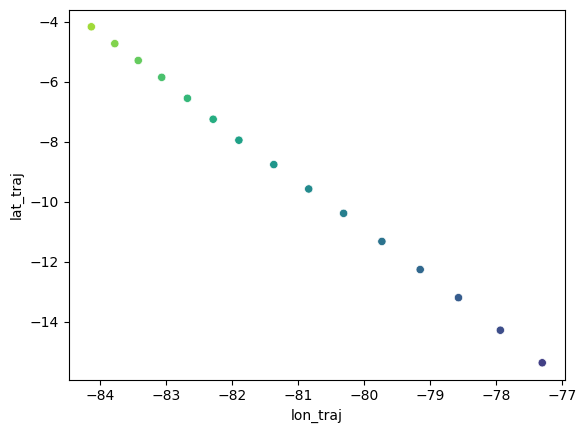

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(data=bt_SEP_hourly.isel(time_startpoint=-250), x='lon_traj', y='lat_traj', hue='datetime_traj', palette='viridis', legend=False)

# run the judge CNN on GOES data along these trajectories

In [7]:
def load_and_prepare_goes_data(date, time):
    ts = pd.to_datetime(date + time)

    lat_bounds, lon_bounds, times = judge_goes19.setup_region_parameters(region='SEP')
    data_dir='/home/jmayer/Object_Data/GOES19/'

    print('.' * 85)
    print(f"Processing date {date} time {time}...")

    if not os.path.exists(f'{data_dir}/goes19_C11_RadF_{date}_{time}.nc'):
        print(f"GOES C11 data for {date} {time} not found. Skipping.")
        return None, None, None, None

    # Load and crop GOES data
    print("Loading C11 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C11_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_11_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading C14 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C14_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_14_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading C15 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C15_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_15_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading COD data...")
    with xr.open_dataset(f'{data_dir}/goes19_COD2KMF_{date}_{time}.nc') as ds:
        ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    return ds_11_cropped, ds_14_cropped, ds_15_cropped, ds_COD_cropped


def find_closest_goes_grid_points(goes_latitudes, goes_longitudes, traj_lats, traj_lons):
    """
    Find the closest grid points in the latitude and longitude arrays for each trajectory point.
    """

    # Find closest grid points for each trajectory point using two-step approach
    traj_goes_indices_x = []
    traj_goes_indices_y = []
    for traj_lat, traj_lon in zip(traj_lats, traj_lons):
        # Step 1: Filter coordinates to within 0.1 degree of trajectory point
        lat_diff = np.abs(goes_latitudes - traj_lat)
        lon_diff = np.abs(goes_longitudes - traj_lon)
        within_bounds = (lat_diff <= 0.1) & (lon_diff <= 0.1)
        
        if not np.any(within_bounds):
            print(f"Warning: No grid points within 0.1 degree of trajectory point ({traj_lat:.2f}, {traj_lon:.2f})")
            continue
        
        # Step 2: Calculate distance only for points within bounds
        distance_sq = np.full_like(goes_latitudes, np.inf)  # Initialize with infinity
        distance_sq[within_bounds] = (lat_diff[within_bounds])**2 + (lon_diff[within_bounds])**2
        
        # Find indices of minimum distance
        min_idx = np.unravel_index(np.argmin(distance_sq), distance_sq.shape)
        traj_goes_indices_x.append(min_idx[1])
        traj_goes_indices_y.append(min_idx[0])

    return np.array(traj_goes_indices_x), np.array(traj_goes_indices_y)


def load_model(model_path):
    """Load the fine-tuned model from disk"""
    device_num = '0'  # Change this to your GPU number or 'cpu'
    device = torch.device(f'cuda:{device_num}' if torch.cuda.is_available() and device_num != 'cpu' else 'cpu')
    
    model = timm.create_model('resnet50d', pretrained=False)
    model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(2048, 6)
    model = model.to(device)
    
    weights = torch.load(model_path, map_location=device)
    model.load_state_dict(weights)
    model.eval()
    
    print(f"Loaded fine-tuned model from {model_path}")
    return model

# apply the fine tuned model to the preprocessed data
class GOESDataset(Dataset):
    def __init__(self, data):
        self.data = torch.FloatTensor(data)
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        return self.data[idx]

def run_judge_on_goes_data(all_weirgb, fine_tuned_model):
    """
    Run inference using the fine-tuned model on the preprocessed GOES data.
    
    Parameters:
    -----------
    all_weirgb : np.ndarray
        Preprocessed GOES data of shape (N, C, H, W)
    fine_tuned_model : torch.nn.Module
        The fine-tuned model for inference
    
    Returns:
    --------
    predictions : np.ndarray
        Predicted class labels for each input sample
    probabilities : np.ndarray
        Class probabilities for each input sample
    """

    # Set up device
    device_num = '0'
    device = torch.device(f'cuda:{device_num}' if torch.cuda.is_available() and device_num != 'cpu' else 'cpu')

    # Create dataset and dataloader
    dataset = GOESDataset(all_weirgb)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=False)

    # Run inference
    predictions = []
    probabilities = []

    print(f"Running inference on {len(all_weirgb)} samples...")

    with torch.no_grad():
        for batch_idx, batch in enumerate(dataloader):
            batch = batch.to(device)
            
            # Forward pass
            outputs = fine_tuned_model(batch)
            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(outputs, dim=1)
            
            # Store results
            predictions.extend(preds.cpu().numpy())
            probabilities.extend(probs.cpu().numpy())
            
            # Progress update
            if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(dataloader):
                print(f"Processed {min((batch_idx + 1) * 32, len(all_weirgb))}/{len(all_weirgb)} samples")

    predictions = np.array(predictions)
    probabilities = np.array(probabilities)

    return predictions, probabilities

In [8]:
def summary_plot_results(df_traj_points_at_datetime, COD):
    from matplotlib.colors import ListedColormap
    print("Results summary:")
    print(f"\nClass distribution:")
    for class_id in range(6):
        count = np.sum(df_traj_points_at_datetime['goes_cats'].values == class_id)
        percentage = 100 * count / len(df_traj_points_at_datetime['goes_cats'].values)
        print(f"Class {class_id}: {count} samples ({percentage:.1f}%)")

    # Plot spatial distribution of predictions
    fig, ax = plt.subplots(1, 1, figsize=(8, 6))
    scale_factor = 2  # 2x upscaling for COD2KMF; 4x upsampling is needed if CODF is used
    COD_interpolated = zoom(COD.values, scale_factor, order=1)
    # Create new xarray DataArray
    COD_interpolated = xr.DataArray(
        COD_interpolated,
        dims=['y', 'x']
    )
    ax.imshow(COD_interpolated, vmax=40, vmin=0, cmap='Greys_r')
    colors = [palette_goes_cats[i] for i in range(6)]
    custom_cmap = ListedColormap(colors, name='goes_classes')
    scatter = ax.scatter(df_traj_points_at_datetime['goes_x_idx'], df_traj_points_at_datetime['goes_y_idx'], 
                        c=df_traj_points_at_datetime['goes_cats'], cmap=custom_cmap, vmin=0, vmax=5, alpha=0.7)
    plt.colorbar(scatter, ax=ax, label='Class')
    plt.show()

    print(f"\nMean prediction confidence: {df_traj_points_at_datetime['goes_cert'].mean():.3f}")
    print(f"Min prediction confidence: {df_traj_points_at_datetime['goes_cert'].min():.3f}")
    print(f"Max prediction confidence: {df_traj_points_at_datetime['goes_cert'].max():.3f}")

In [9]:
def process_goes_for_trajectory_timestep(date, time, bt_SEP_hourly, fine_tuned_model):
    # Load and prepare GOES data
    ds_11_cropped, ds_14_cropped, ds_15_cropped, ds_COD_cropped = load_and_prepare_goes_data(date, time)
    if ds_11_cropped is None:
        return None
    BT_11, BT_14, BT_15, COD = ds_11_cropped['BT'], ds_14_cropped['BT'], ds_15_cropped['BT'], ds_COD_cropped['COD']

    # get trajectory points for the current date and time
    traj_points_at_datetime = bt_SEP_hourly.where(bt_SEP_hourly.datetime_traj.dt.strftime('%Y%m%d%H%M') == date + time, drop=True)
    #sns.scatterplot(x=traj_points_at_datetime['lon_traj'].values.flatten(), y=traj_points_at_datetime['lat_traj'].values.flatten())
    # transform to dataframe for easier handling
    df_traj_points_at_datetime = traj_points_at_datetime.to_dataframe().reset_index()
    df_traj_points_at_datetime.dropna(subset=['lat_traj', 'lon_traj'], inplace=True)

    # get GOES latitude and longitude values (zoomed by the scale factor that is also used for the CNN)
    scale_factor = 2
    latitudes = zoom(BT_11.latitude.values, scale_factor, order=1)
    longitudes = zoom(BT_11.longitude.values, scale_factor, order=1)

    traj_goes_indices_x, traj_goes_indices_y = find_closest_goes_grid_points(latitudes, longitudes, 
                                                                            df_traj_points_at_datetime['lat_traj'].values, 
                                                                            df_traj_points_at_datetime['lon_traj'].values)

    # Preprocess data for model input
    xy_indices = list(zip(traj_goes_indices_x, traj_goes_indices_y))
    all_weirgb, all_scenes_params = judge_goes19.preprocess_data(BT_11, BT_14, BT_15, COD, window_size=128, xy_indices=xy_indices, debugging=False)

    # Run inference
    predictions, probabilities = run_judge_on_goes_data(all_weirgb, fine_tuned_model)
    print(f"Inference complete!")
    print(f"Predictions shape: {predictions.shape}")
    print(f"Probabilities shape: {probabilities.shape}")
    print(f"Class distribution: {np.bincount(predictions)}")

    # save judge results to dataframe
    df_traj_points_at_datetime['goes_cats'] = predictions
    df_traj_points_at_datetime['goes_cert'] = np.max(probabilities, axis=1)
    df_traj_points_at_datetime['goes_cats'] = np.where(np.isnan(df_traj_points_at_datetime['goes_cert']), np.nan, df_traj_points_at_datetime['goes_cats'])
    df_traj_points_at_datetime['goes_ice_flag'] = all_scenes_params['ice_flag']
    df_traj_points_at_datetime['goes_y_idx'] = all_scenes_params['y_idx']
    df_traj_points_at_datetime['goes_x_idx'] = all_scenes_params['x_idx']
    df_traj_points_at_datetime['goes_lat_mid'] = all_scenes_params['lat_mid']
    df_traj_points_at_datetime['goes_lon_mid'] = all_scenes_params['lon_mid']
    df_traj_points_at_datetime.set_index(['time_startpoint', 'timestep'], inplace=True)
    df_traj_points_at_datetime.drop(columns=['orbit'], inplace=True) # remove orbit, otherwise it gets messy to bring it to a coordinate in the resulting xarray (and not a dimension or variable)

    # TODO: save CC, computed from COD == 0

    summary_plot_results(df_traj_points_at_datetime, COD)
    
    results_at_datetime = df_traj_points_at_datetime.to_xarray()
    #results_at_datetime = results_at_datetime.assign_coords(orbit=('time_startpoint', results_at_datetime['orbit'].data))
        
    return results_at_datetime

In [10]:
results = bt_SEP_hourly.copy()
results['goes_cats'] = (('time_startpoint', 'timestep'), np.full(bt_SEP_hourly['lat_traj'].shape, np.nan))
results['goes_cert'] = (('time_startpoint', 'timestep'), np.full(bt_SEP_hourly['lat_traj'].shape, np.nan))
results['goes_ice_flag'] = (('time_startpoint', 'timestep'), np.full(bt_SEP_hourly['lat_traj'].shape, np.nan))
results['goes_y_idx'] = (('time_startpoint', 'timestep'), np.full(bt_SEP_hourly['lat_traj'].shape, np.nan))
results['goes_x_idx'] = (('time_startpoint', 'timestep'), np.full(bt_SEP_hourly['lat_traj'].shape, np.nan))
results['goes_lon_mid'] = (('time_startpoint', 'timestep'), np.full(bt_SEP_hourly['lat_traj'].shape, np.nan))
results['goes_lat_mid'] = (('time_startpoint', 'timestep'), np.full(bt_SEP_hourly['lat_traj'].shape, np.nan))

if os.path.isfile('/home/jmayer/ACI_research/Code/resources/bt_with_goes_partial.nc'):
    with xr.open_dataset('/home/jmayer/ACI_research/Code/resources/bt_with_goes_partial.nc') as results_existing:
        print("Loading existing results from disk...")
        results_existing.load()

    # Update results only where coordinates match with results_existing
    results = results.combine_first(results_existing)

Loading existing results from disk...


In [12]:
results.goes_cats

<xarray.DataArray 'goes_cats' (time_startpoint: 1577, timestep: 43)> Size: 542kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(1577, 43))
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 13kB 2025-07-01T19:54:3...
    orbit            (time_startpoint, timestep) <U6 2MB '06206E' ... '07155E'
  * timestep         (timestep) int64 344B -42 -40 -38 -36 -34 ... 36 38 40 42

In [13]:
# available GOES times
time_list = ['1400', '1600', '1800', '2000', '2200']
day_list = [f'{i:02d}' for i in range(1, 32)]

In [16]:
fine_tuned_model_path = '../judge_for_goes/finetuned_goes_model.pth'
fine_tuned_model = load_model(fine_tuned_model_path)

for month in ['07', '08']:
    for day in day_list:
        date='2025' + month + day
        for time in time_list:
            # check if GOES data has already been processed for this date and time
            goes_cats_at_datetime = results.where(results.datetime_traj.dt.strftime('%Y%m%d%H%M') == date + time, drop=True).goes_cats
            if len(goes_cats_at_datetime) == 0:
                print(f"Datetime does not exist in trajectory data: {date} {time}. Something went wrong.")
                break
            if ~np.isnan(goes_cats_at_datetime).all():
                print(f"GOES data already processed for {date} {time}. Skipping.")
                continue

            results_at_datetime = process_goes_for_trajectory_timestep(date, time, bt_SEP_hourly, fine_tuned_model)
            if results_at_datetime is not None:
                results = xr.merge([results, results_at_datetime])
                print(f"Updated results dataset for {date} {time}\n")

            results.to_netcdf('/home/jmayer/ACI_research/Code/resources/bt_with_goes_partial.nc', 
                    engine='h5netcdf')
        
results.to_netcdf('/home/jmayer/ACI_research/Code/resources/bt_with_goes.nc', 
                  engine='h5netcdf')

/tmp/ipykernel_4173651/1319648494.py:77: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  weights = torch.load(model_path, map_location=device)


Loaded fine-tuned model from ../judge_for_goes/finetuned_goes_model.pth
GOES data already processed for 20250701 1400. Skipping.
GOES data already processed for 20250701 1600. Skipping.
GOES data already processed for 20250701 1800. Skipping.
GOES data already processed for 20250701 2000. Skipping.
GOES data already processed for 20250701 2200. Skipping.
GOES data already processed for 20250702 1400. Skipping.
GOES data already processed for 20250702 1600. Skipping.
GOES data already processed for 20250702 1800. Skipping.
GOES data already processed for 20250702 2000. Skipping.
GOES data already processed for 20250702 2200. Skipping.
GOES data already processed for 20250703 1400. Skipping.
GOES data already processed for 20250703 1600. Skipping.
GOES data already processed for 20250703 1800. Skipping.
GOES data already processed for 20250703 2000. Skipping.
GOES data already processed for 20250703 2200. Skipping.
GOES data already processed for 20250704 1400. Skipping.
GOES data alread

/home/jmayer/ACI_research/Code/mesoscale_structure/backtrajectories/../judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/backtrajectories/../judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81
Loading C14 data...


/home/jmayer/ACI_research/Code/mesoscale_structure/backtrajectories/../judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/backtrajectories/../judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81
Loading C15 data...


/home/jmayer/ACI_research/Code/mesoscale_structure/backtrajectories/../judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/backtrajectories/../judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81
Loading COD data...


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/home/jmayer/Object_Data/GOES19/goes19_COD2KMF_20250730_1800.nc', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [37]:
def make_sure_orbit_consistent_along_trajectories(results):
    """
    Ensure that the 'orbit' variable is consistent along the 'timestep' dimension for each trajectory.
    If inconsistent, raise an error. If consistent, reduce 'orbit' to only depend on 'time_startpoint'.
    
    Parameters:
    -----------
    results : xarray.Dataset
        Dataset containing the 'orbit' variable with dimensions ('time_startpoint', 'timestep')
    
    Returns:
    --------
    xarray.Dataset
        Updated dataset with 'orbit' variable reduced to ('time_startpoint') dimension
    """
    if results.orbit.dims == ('time_startpoint', 'timestep'):
        # check if orbit is the same along 'timestep' dimension for each trajectory
        groups = results.orbit.groupby('time_startpoint')
        for date_time, group in groups:
            unique_orbits = np.unique(group.values)
            if (len(unique_orbits)) != 1:
                print('several orbits found for trajectory starting at:')
                print(date_time)
                raise ValueError('Orbit inconsistency found along trajectory timesteps.')
            
        print("Orbit consistency check passed: each trajectory has a single orbit along its timesteps.")
        results['orbit'] = results.orbit.sel(timestep=0)

        return results
    
    elif results.orbit.dims == ('time_startpoint',):
        print("Orbit variable already consistent along trajectories.")
        return results
    
    else:
        raise ValueError("Unexpected dimensions for 'orbit' variable.")

results = make_sure_orbit_consistent_along_trajectories(results)
results

Orbit variable already consistent along trajectories.


<xarray.Dataset> Size: 6MB
Dimensions:          (time_startpoint: 1577, timestep: 43)
Coordinates:
  * time_startpoint  (time_startpoint) datetime64[ns] 13kB 2025-07-01T19:54:3...
  * timestep         (timestep) int64 344B -42 -40 -38 -36 -34 ... 36 38 40 42
    orbit            (time_startpoint) <U6 38kB '06206E' '06206E' ... '07155E'
Data variables:
    lat_traj         (time_startpoint, timestep) float64 542kB nan nan ... nan
    lon_traj         (time_startpoint, timestep) float64 542kB nan nan ... nan
    plev_traj        (time_startpoint, timestep) float64 542kB nan nan ... nan
    datetime_traj    (time_startpoint, timestep) datetime64[ns] 542kB NaT ......
    goes_cats        (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_cert        (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_ice_flag    (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_y_idx       (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_x_idx       (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_lon_mid     (time_startpoint, timestep) float64 542kB nan nan ... nan
    goes_lat_mid     (time_startpoint, timestep) float64 542kB nan nan ... nan

In [ ]:
results.to_netcdf('/home/jmayer/ACI_research/Code/resources/bt_with_goes.nc', 
                  engine='h5netcdf')